### Import libraries and set random seeds

This cell imports the libraries for data processing, neural network training, and evaluation. It checks that Python is at least version 3.10 and sets the Python, NumPy, and PyTorch random seeds to 42. It clears the GPU cache and sets cuDNN options to reduce run-to-run variation, although these settings do not guarantee identical results across all environments.


In [ ]:
import os
import sys

if sys.version_info < (3, 10):
    raise RuntimeError("This notebook requires a Jupyter kernel running Python 3.10 or later.")

from pathlib import Path
from IPython.display import display
import time
import random
import gc
import joblib

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix,
)
from sklearn.model_selection import train_test_split


# Release unused memory
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


### Set the input path and experiment options

Set the CSV path and check that the file exists. The current settings use batches of 64, blocks of 1,000 rows, windows of 30 rows, and target train/validation/test proportions of 70%/10%/20%. This cell also sets the early-stopping and ONNX-export options and gives `seq_length` the same value as `SEQ_LENGTH` for the later sample-generation cells.


In [ ]:
csv_path = 'C:\\Users\\pando\\Documents\\Codex\\2026-11-02\\pdf-2\\work\\source_archive\\1. MCU IDS.vol1\\dataset\\master_dataset_unseen_seed2952.csv'

if not Path(csv_path).is_file():
    raise FileNotFoundError(csv_path)

batch_size = 64
BLOCK_SIZE = 1000
SEQ_LENGTH = 30
seq_length = SEQ_LENGTH
TRAIN_RATIO = 0.7
VAL_RATIO = 0.1
TEST_RATIO = 0.2
NUM_CLASSES = 25
NUM_CCSDS_CLASSES = 5
NUM_CAN_CLASSES = 5
ENABLE_EARLY_STOPPING = True
EARLY_STOP_PATIENCE = 5
EXPORT_ONNX = True


### Define windows within each block

This dataset class receives feature values, labels, and block identifiers. It creates windows of the configured length, currently 30 rows, with a stride of one row inside each block. The final row's label becomes the window's target; windows never cross block boundaries, and blocks shorter than the window length produce no samples.


In [4]:
class BlockSequenceDataset(Dataset):
    def __init__(self, features, labels, groups, seq_length=10):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)
        self.groups = np.asarray(groups)
        self.seq_length = seq_length

        assert len(self.features) == len(self.labels) == len(self.groups), (
            "features, labels, groups must have the same length."
        )

        assert len(self.features) >= self.seq_length, (
            f"Data length ({len(self.features)}) is shorter than seq_length ({self.seq_length})."
        )

        self.start_indices = self._build_start_indices()

        assert len(self.start_indices) > 0, (
            "No valid sequences can be generated. Check the block size or seq_length."
        )

    def _build_start_indices(self):
        starts = []
        n = len(self.groups)

        start = 0

        while start < n:
            current_group = self.groups[start]
            end = start + 1

            while end < n and self.groups[end] == current_group:
                end += 1

            group_len = end - start

            if group_len >= self.seq_length:
                group_starts = np.arange(
                    start,
                    end - self.seq_length + 1,
                    dtype=np.int64,
                )
                starts.append(group_starts)

            start = end

        if len(starts) == 0:
            return np.array([], dtype=np.int64)

        return np.concatenate(starts)

    def __len__(self):
        return len(self.start_indices)

    def __getitem__(self, idx):
        start_idx = self.start_indices[idx]
        end_idx = start_idx + self.seq_length

        x_window = self.features[start_idx:end_idx]
        y_target = self.labels[end_idx - 1]

        return x_window, y_target

### Calculate the byte length of a hexadecimal payload

This helper removes spaces and a leading `0x` from a hexadecimal payload string, then calculates its length in bytes. It returns zero for missing values or strings that cannot be parsed as hexadecimal data. The payload-correction cell below calls this function.


In [5]:
def hex_payload_len(x):
    if pd.isna(x):
        return 0

    s = str(x).strip().replace(" ", "")

    if s.startswith("0x"):
        s = s[2:]

    try:
        bytes.fromhex(s)
        return len(s) // 2
    except ValueError:
        return 0

### Assign block identifiers to observations

This function groups observations using the available trace, file, and run identifiers together with `Combined_Label`. It sorts each group by time, divides it into blocks of up to 1,000 rows, and combines the group information and block number into `Global_Block_ID`. The split and window-generation steps use this identifier to preserve block boundaries.


In [6]:
def add_global_block_id(df, block_size=1000):
    df = df.copy()

    group_cols = [
        c for c in [
            "Trace_ID",
            "Source_File",
            "Run_ID",
            "Combined_Label",
        ]
        if c in df.columns
    ]

    if len(group_cols) == 0:
        group_cols = ["Combined_Label"]

    sort_cols = group_cols + ["Timestamp"] if "Timestamp" in df.columns else group_cols

    df = df.sort_values(sort_cols).reset_index(drop=True)

    df["_row_in_group"] = df.groupby(group_cols, sort=False).cumcount()
    df["Block_ID"] = (df["_row_in_group"] // block_size).astype(int)

    df["Global_Block_ID"] = (
        df[group_cols].astype(str).agg("_".join, axis=1)
        + "_block_"
        + df["Block_ID"].astype(str)
    )

    df = df.drop(columns=["_row_in_group"])

    return df

### Read the CSV and sort observations by time

Read the specified CSV into `df` and sort its rows by `Timestamp`. Resetting the index gives the later preprocessing steps a consistent row order. This cell reads an existing dataset; it does not generate raw communication traffic or calculate new derived features.


In [7]:
start_time = time.time()

df = pd.read_csv(csv_path)
df = df.sort_values(by="Timestamp").reset_index(drop=True)

### Combine the two protocol labels

Calculate `Combined_Label` as `CCSDS_Label * 5 + CAN_Label`. Check that the resulting values fall between 0 and 24. The combined label is used for splitting and training targets, but is not included among the model's input features.


In [8]:
df["Combined_Label"] = (
    df["CCSDS_Label"].astype(int) * NUM_CAN_CLASSES
    + df["CAN_Label"].astype(int)
)

assert df["Combined_Label"].min() >= 0
assert df["Combined_Label"].max() < NUM_CLASSES
print("Combined_Label created.")

Combined_Label created.


### Correct payload lengths stored as strings

If `Payload_Len` has object dtype, treat its values as hexadecimal payload strings and recalculate their byte lengths. Keep the original strings in `Raw_Hex` and store the calculated lengths as `float32`. This cell leaves an already numeric `Payload_Len` column unchanged.


In [9]:
if df["Payload_Len"].dtype == "object":
    print("Payload_Len is object type. Recomputing as byte length.")
    df["Raw_Hex"] = df["Payload_Len"].astype(str)
    df["Payload_Len"] = df["Raw_Hex"].apply(hex_payload_len).astype(np.float32)

### Select the 23 input features

Specify the order of 13 base features and 10 derived features that describe timing, changes, and recent observations. Remove duplicate names and stop if any required column is missing from the CSV. This cell selects derived features rather than calculating them, so all 23 columns must already exist in the input file.


In [10]:
base_features = [
    "CCSDS_APID",
    "CCSDS_DataLen",

    "CSP_Priority",
    "CSP_Source",
    "CSP_Dest",
    "CSP_DPort",
    "CSP_SPort",
    "CSP_Flags",

    "Payload_Len",

    "Time_Delta_Log",
    "Flags_Change",
    "Payload_Diff",
    "APID_Count",

    # "P_Mean",
    # "P_Std",
    # "P_Entropy_Log",
    # "P_First",
    # "P_Entropy_Diff",
    # "P_Sum",
    # "P_Sum_Diff",
]

compact_engineered_features = [
    "Global_Time_Delta_Log",
    "APID_Time_Delta_Log",
    "APID_Changed_Roll10",
    "CCSDS_DataLen_AbsDiff",
    "CCSDS_SeqCount_AbsDiff",
    "Packet_Rate_Roll10_Log",
    "CSP_Nonzero_Roll10",
    "CSP_Route_Changed_Roll10",
    "Payload_Len_RollStd10",
    "P_Entropy_Log_RollStd10",
]

features_to_keep = base_features + compact_engineered_features
features_to_keep = list(dict.fromkeys(features_to_keep))

missing_cols = [c for c in features_to_keep if c not in df.columns]
assert len(missing_cols) == 0, f"Missing features: {missing_cols}"

print("Final number of features:", len(features_to_keep))

Final number of features: 23


### Split blocks into training, validation, and test sets

Create the block identifiers, then split blocks while stratifying by their combined labels. Use random seed 42 and check that no block belongs to more than one partition. Finally, sort each partition by block and time and print its row and block counts.


In [11]:
df_clean = df.copy().reset_index(drop=True)
df_clean = add_global_block_id(df_clean, block_size=BLOCK_SIZE)

block_table = (
    df_clean[["Global_Block_ID", "Combined_Label"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

assert block_table["Global_Block_ID"].is_unique, (
    "A single Global_Block_ID maps to multiple Combined_Labels."
)

print("Total blocks:", len(block_table))
print("Block label distribution:")
print(block_table["Combined_Label"].value_counts().sort_index())

train_blocks, temp_blocks = train_test_split(
    block_table,
    test_size=(VAL_RATIO + TEST_RATIO),
    random_state=SEED,
    stratify=block_table["Combined_Label"],
)

relative_test_ratio = TEST_RATIO / (VAL_RATIO + TEST_RATIO)

val_blocks, test_blocks = train_test_split(
    temp_blocks,
    test_size=relative_test_ratio,
    random_state=SEED,
    stratify=temp_blocks["Combined_Label"],
)

train_block_set = set(train_blocks["Global_Block_ID"])
val_block_set = set(val_blocks["Global_Block_ID"])
test_block_set = set(test_blocks["Global_Block_ID"])

assert train_block_set.isdisjoint(val_block_set)
assert train_block_set.isdisjoint(test_block_set)
assert val_block_set.isdisjoint(test_block_set)


train_df = df_clean[df_clean["Global_Block_ID"].isin(train_block_set)].copy()
val_df = df_clean[df_clean["Global_Block_ID"].isin(val_block_set)].copy()
test_df = df_clean[df_clean["Global_Block_ID"].isin(test_block_set)].copy()


def sort_block_split(df_part):
    sort_cols = ["Global_Block_ID"]
    if "Timestamp" in df_part.columns:
        sort_cols.append("Timestamp")

    return df_part.sort_values(sort_cols).reset_index(drop=True)


train_df = sort_block_split(train_df)
val_df = sort_block_split(val_df)
test_df = sort_block_split(test_df)

print("-" * 60)
print("Block-wise split complete")
print("Train rows:", len(train_df), "| blocks:", train_df["Global_Block_ID"].nunique())
print("Val rows:", len(val_df), "| blocks:", val_df["Global_Block_ID"].nunique())
print("Test rows:", len(test_df), "| blocks:", test_df["Global_Block_ID"].nunique())

Total blocks: 1500
Block label distribution:
Combined_Label
0     100
1      50
2      50
3      50
4      50
5     100
6      50
7      50
8      50
9      50
10    100
11     50
12     50
13     50
14     50
15    100
16     50
17     50
18     50
19     50
20    100
21     50
22     50
23     50
24     50
Name: count, dtype: int64
------------------------------------------------------------
Block-wise split complete
Train rows: 1049000 | blocks: 1049
Val rows: 150000 | blocks: 150
Test rows: 301000 | blocks: 301


### Convert values and standardize using training data

Convert the selected features to numbers and replace missing or unparseable values with zero. Fit `StandardScaler` on training rows only, then apply the same transformation to the validation and test rows. Convert the results to `float32` and save the scaler as `scaler.pkl` for later reuse.


In [12]:
X_train_raw = train_df[features_to_keep].copy()
X_val_raw = val_df[features_to_keep].copy()
X_test_raw = test_df[features_to_keep].copy()

X_train_raw = X_train_raw.apply(pd.to_numeric, errors="coerce").fillna(0)
X_val_raw = X_val_raw.apply(pd.to_numeric, errors="coerce").fillna(0)
X_test_raw = X_test_raw.apply(pd.to_numeric, errors="coerce").fillna(0)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

### Build the target and block arrays

Extract the combined labels and block identifiers for each partition. Check that each feature array has the same number of rows as its target and block arrays. The next cell uses these aligned arrays to connect each input window with its target.


In [13]:
y_train = train_df["Combined_Label"].astype(int).values
y_val = val_df["Combined_Label"].astype(int).values
y_test = test_df["Combined_Label"].astype(int).values

group_train = train_df["Global_Block_ID"].astype(str).values
group_val = val_df["Global_Block_ID"].astype(str).values
group_test = test_df["Global_Block_ID"].astype(str).values

assert len(X_train) == len(y_train) == len(group_train)
assert len(X_val) == len(y_val) == len(group_val)
assert len(X_test) == len(y_test) == len(group_test)

### Create window datasets and DataLoaders

Build the 30-row window datasets from the standardized features and block identifiers. The training DataLoader shuffles samples and drops the final batch if it contains fewer than 64 samples. The validation and test DataLoaders preserve sample order and include their final partial batches.


In [14]:
train_dataset = BlockSequenceDataset(X_train, y_train, group_train, seq_length=SEQ_LENGTH)
val_dataset = BlockSequenceDataset(X_val, y_val, group_val, seq_length=SEQ_LENGTH)
test_dataset = BlockSequenceDataset(X_test, y_test, group_test, seq_length=SEQ_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, drop_last=False)

### Check preprocessing dimensions and class coverage

Print the row counts, window counts, class lists, and missing classes for each partition. Inspect the first input and target from each dataset. Check that the feature count and input shape match the current `(30, 23)` configuration, and report the preprocessing time.


In [15]:
print("-" * 60)
print("Preprocessing complete!")
print(f"X_train shape: {X_train.shape}")
print(f"X_val shape: {X_val.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train: {len(y_train)}")
print(f"y_val: {len(y_val)}")
print(f"y_test: {len(y_test)}")
print(f"train_dataset: {len(train_dataset)}")
print(f"val_dataset: {len(val_dataset)}")
print(f"test_dataset: {len(test_dataset)}")

print("Train classes:", sorted(np.unique(y_train)))
print("Val classes:", sorted(np.unique(y_val)))
print("Test classes:", sorted(np.unique(y_test)))

print("Classes missing in Train:", set(range(NUM_CLASSES)) - set(np.unique(y_train)))
print("Classes missing in Val:", set(range(NUM_CLASSES)) - set(np.unique(y_val)))
print("Classes missing in Test:", set(range(NUM_CLASSES)) - set(np.unique(y_test)))

x0, y0 = train_dataset[0]
xv, yv = val_dataset[0]
xt, yt = test_dataset[0]

print("train x shape:", x0.shape, "y:", y0)
print("val x shape:", xv.shape, "y:", yv)
print("test x shape:", xt.shape, "y:", yt)

assert X_train.shape[1] == len(features_to_keep)
assert X_val.shape[1] == len(features_to_keep)
assert X_test.shape[1] == len(features_to_keep)
assert x0.shape == torch.Size([SEQ_LENGTH, len(features_to_keep)])
assert xv.shape == torch.Size([SEQ_LENGTH, len(features_to_keep)])
assert xt.shape == torch.Size([SEQ_LENGTH, len(features_to_keep)])

print(f"Preprocessing time: {time.time() - start_time:.2f}s")

------------------------------------------------------------
Preprocessing complete!
X_train shape: (1049000, 23)
X_val shape: (150000, 23)
X_test shape: (301000, 23)
y_train: 1049000
y_val: 150000
y_test: 301000
train_dataset: 1018579
val_dataset: 145650
test_dataset: 292271
Train classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Val classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Test classes:

### Define focal loss from weighted cross-entropy

First calculate class-weighted cross-entropy `ce`, then use `exp(-ce)` to form the focal factor. The loss is `alpha * (1 - exp(-ce))**gamma * ce`, with the batch mean returned by default. The class weights therefore affect the focal factor as well as cross-entropy, which differs from applying weights only after focal modulation.


In [16]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2, reduction='mean', weight=None):
        super(FocalLoss, self).__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        self.weight = weight # Optional per-class weights

    def forward(self, inputs, targets):
        # 1. Compute cross-entropy loss, including log-softmax
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.weight)

        # 2. Compute the focal weighting term pt = exp(-ce_loss)
        pt = torch.exp(-ce_loss)

        # 3. Apply the focal loss formula: alpha * (1-pt)^gamma * ce_loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

### Select the computation device

Choose a CUDA GPU when one is available; otherwise, use the CPU. Print the selected device. The later training cells move the model and its inputs to this device.


In [17]:
# Use a GPU when available; otherwise use the CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"{device}")

cuda


### Prepare class weights and the loss function

Calculate class frequencies from the training-row labels after excluding the first 29 rows of the entire training partition. Cap the inverse-frequency weights at 10 and pass them to Focal Loss with `alpha=1` and `gamma=2`. These labels are not the same set as the actual window targets obtained by excluding the first 29 rows of every block.


In [18]:
train_targets = y_train[SEQ_LENGTH - 1:]
present_classes = np.unique(train_targets)

class_weights_present = compute_class_weight(
    class_weight='balanced',
    classes=present_classes,
    y=train_targets
)

weights = np.ones(NUM_CLASSES, dtype=np.float32)
weights[present_classes] = class_weights_present

custom_weights = torch.tensor(weights, dtype=torch.float32).to(device)
custom_weights = torch.clamp(custom_weights, max=10.0)

criterion = FocalLoss(alpha=1, gamma=2, weight=custom_weights)

### Train the CNN and select its weights

This CNN has two convolutional blocks and a 64-unit hidden layer; its `StudentSTFake2DCNN` class name does not imply knowledge distillation or a teacher model. Adam uses a learning rate of 0.001 for up to 15 epochs while the code records training loss, accuracy, and validation Macro-F1. With the current settings, training stops after five consecutive epochs without an improvement in validation Macro-F1, then restores the weights with the highest validation score. Best-weight selection and restoration remain enabled even when early stopping is disabled.


In [19]:
# Imports are loaded in the library imports and configuration cell

# ==========================================
# 1. Define the lightweight student model for STM32
# ==========================================
class StudentSTFake2DCNN(nn.Module):
    def __init__(self, seq_length=SEQ_LENGTH, num_features=len(features_to_keep), num_classes=25):
        super().__init__()

        self.conv = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=(1, 5), padding=(0, 2)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),

            nn.Conv2d(8, 16, kernel_size=(3, 3), padding=(1, 1)),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1)),
        )

        flattened_dim = (seq_length // 4) * num_features * 16

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flattened_dim, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        x = x.unsqueeze(1)  # (B, 1, seq, feat)
        x = self.conv(x)
        x = self.classifier(x)
        return x

# ==========================================
# 2. Initialize the model and optimizer
# ==========================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = StudentSTFake2DCNN(
    seq_length=SEQ_LENGTH,
    num_features=len(features_to_keep),
    num_classes=25
).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ==========================================
# 3. Train the model and record its history
# ==========================================
num_epochs = 15
total_elapsed_time = 0

# ── Training history storage ──
train_history = {
    "epoch": [],
    "loss": [],
    "acc_combined": [],
    "acc_ccsds": [],
    "acc_can": [],
    "val_acc": [],
    "val_macro_f1": [],
    "elapsed_s": [],
}

# ── Early stopping configuration ──
best_val_metric = 0.0
best_model_state = None
es_counter = 0
es_triggered = False

print("Training started!" + (" (Early Stopping ON)" if ENABLE_EARLY_STOPPING else ""))
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_combined = 0
    correct_ccsds = 0
    correct_can = 0
    total = 0
    start_time = time.time()

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs_student = model(inputs)
        loss = criterion(outputs_student, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, preds = torch.max(outputs_student, 1)
        pred_ccsds = preds // 5
        pred_can = preds % 5
        target_ccsds = labels // 5
        target_can = labels % 5

        correct_combined += (preds == labels).sum().item()
        correct_ccsds += (pred_ccsds == target_ccsds).sum().item()
        correct_can += (pred_can == target_can).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_acc_combined = 100 * correct_combined / total
    epoch_acc_ccsd = 100 * correct_ccsds / total
    epoch_acc_can = 100 * correct_can / total
    elapsed_time = time.time() - start_time
    total_elapsed_time += elapsed_time

    # ── Validation evaluation ──
    model.eval()
    val_preds_list, val_labels_list = [], []
    with torch.no_grad():
        for v_inputs, v_labels in val_loader:
            v_inputs = v_inputs.to(device)
            v_out = model(v_inputs)
            val_preds_list.extend(v_out.argmax(dim=1).cpu().numpy())
            val_labels_list.extend(v_labels.numpy())
    val_acc = 100 * accuracy_score(val_labels_list, val_preds_list)
    val_mf1 = f1_score(val_labels_list, val_preds_list, average="macro", zero_division=0)

    # ── Record training history ──
    train_history["epoch"].append(epoch + 1)
    train_history["loss"].append(epoch_loss)
    train_history["acc_combined"].append(epoch_acc_combined)
    train_history["acc_ccsds"].append(epoch_acc_ccsd)
    train_history["acc_can"].append(epoch_acc_can)
    train_history["val_acc"].append(val_acc)
    train_history["val_macro_f1"].append(val_mf1 * 100)
    train_history["elapsed_s"].append(elapsed_time)

    print(
        f"[Epoch {epoch+1:2d}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Train Acc: {epoch_acc_combined:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Val F1: {val_mf1*100:.2f}% | "
        f"Time: {elapsed_time:.2f}s"
    )

    # ── Check early stopping ──
    if ENABLE_EARLY_STOPPING:
        if val_mf1 > best_val_metric:
            best_val_metric = val_mf1
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
            es_counter = 0
        else:
            es_counter += 1
            if es_counter >= EARLY_STOP_PATIENCE:
                print(f"  ⚡ Early Stopping at epoch {epoch+1} (patience={EARLY_STOP_PATIENCE})")
                es_triggered = True
                break
    else:
        # Track the best model even when early stopping is disabled
        if val_mf1 > best_val_metric:
            best_val_metric = val_mf1
            best_model_state = {k: v.clone() for k, v in model.state_dict().items()}

# ── Restore the best model ──
if best_model_state is not None:
    model.load_state_dict(best_model_state)
    print(f"✅ Best model restored (Val Macro F1: {best_val_metric*100:.2f}%)")
if ENABLE_EARLY_STOPPING and es_triggered:
    print(f"   Early stopped: {len(train_history['epoch'])} / {num_epochs} epochs completed")

print(f"\nTotal training time: {total_elapsed_time:.2f}s")
print(f"train_history: {len(train_history['epoch'])} epochs recorded")

Training started! (Early Stopping ON)
[Epoch  1] | Loss: 0.0889 | Train Acc: 91.24% | Val Acc: 96.82% | Val F1: 96.74% | Time: 36.25s
[Epoch  2] | Loss: 0.0186 | Train Acc: 97.72% | Val Acc: 98.04% | Val F1: 98.04% | Time: 39.01s
[Epoch  3] | Loss: 0.0124 | Train Acc: 98.49% | Val Acc: 98.29% | Val F1: 98.24% | Time: 36.71s
[Epoch  4] | Loss: 0.0094 | Train Acc: 98.85% | Val Acc: 98.46% | Val F1: 98.46% | Time: 36.25s
[Epoch  5] | Loss: 0.0075 | Train Acc: 99.08% | Val Acc: 98.69% | Val F1: 98.69% | Time: 35.88s
[Epoch  6] | Loss: 0.0067 | Train Acc: 99.21% | Val Acc: 99.02% | Val F1: 99.02% | Time: 35.74s
[Epoch  7] | Loss: 0.0058 | Train Acc: 99.32% | Val Acc: 98.91% | Val F1: 98.95% | Time: 35.72s
[Epoch  8] | Loss: 0.0054 | Train Acc: 99.35% | Val Acc: 98.87% | Val F1: 98.86% | Time: 35.78s
[Epoch  9] | Loss: 0.0049 | Train Acc: 99.42% | Val Acc: 98.97% | Val F1: 99.09% | Time: 35.76s
[Epoch 10] | Loss: 0.0047 | Train Acc: 99.46% | Val Acc: 98.54% | Val F1: 98.57% | Time: 41.49s
[E

### Evaluate the selected CNN on the test set

Use the model selected by the training cell to predict every test window. Report accuracy, Macro-F1, Weighted-F1, the 25-class confusion matrix, and the classification report. Split the combined labels back into CCSDS and CAN labels to calculate accuracy and confusion matrices for each axis as well.


In [20]:
# ============================================================
# Final test evaluation
# ============================================================
start_time = time.time()

model = model.to(device)
model.eval()

all_preds_combined = []
all_targets = []

print("Model evaluation started...")

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)

        # Handle models that return a tuple or list
        if isinstance(outputs, (tuple, list)):
            outputs = outputs[0]

        combined_pred = torch.argmax(outputs, dim=1)

        all_preds_combined.extend(combined_pred.detach().cpu().numpy())
        all_targets.extend(labels.detach().cpu().numpy())

# Convert predictions and targets to NumPy arrays
all_targets = np.asarray(all_targets, dtype=np.int64)
all_preds_combined = np.asarray(all_preds_combined, dtype=np.int64)

# ============================================================
# Axis label mapping
# Combined_Label = CCSDS_Label * 5 + CAN_Label
# ============================================================

target_ccsds = all_targets // 5
pred_ccsds = all_preds_combined // 5

target_can = all_targets % 5
pred_can = all_preds_combined % 5

# ============================================================
# Main metrics
# ============================================================

test_acc = accuracy_score(all_targets, all_preds_combined)
test_macro_f1 = f1_score(
    all_targets,
    all_preds_combined,
    labels=list(range(NUM_CLASSES)),
    average="macro",
    zero_division=0,
)
test_weighted_f1 = f1_score(
    all_targets,
    all_preds_combined,
    labels=list(range(NUM_CLASSES)),
    average="weighted",
    zero_division=0,
)

test_acc_ccsds = accuracy_score(target_ccsds, pred_ccsds)
test_acc_can = accuracy_score(target_can, pred_can)

# ============================================================
# Display the summary
# ============================================================

print("-" * 80)
print("[Final Test Results]")
print(f"Test Accuracy     : {test_acc * 100:.4f}%")
print(f"Test Macro F1     : {test_macro_f1 * 100:.4f}%")
print(f"Test Weighted F1  : {test_weighted_f1 * 100:.4f}%")
print(f"Test CCSDS Acc    : {test_acc_ccsds * 100:.4f}%")
print(f"Test CAN Acc      : {test_acc_can * 100:.4f}%")
print("-" * 80)

summary_df = pd.DataFrame([
    {
        "model": "Lightweight CNN IDS final",
        "accuracy": test_acc,
        "macro_f1": test_macro_f1,
        "weighted_f1": test_weighted_f1,
        "ccsds_axis_acc": test_acc_ccsds,
        "can_axis_acc": test_acc_can,
    }
])

print("📊 Summary table")
display(summary_df)

# ============================================================
# Confusion matrix: 25-class
# ============================================================

print("-" * 80)
print("[Final Results] 25-class Combined Attack Detection Confusion Matrix")
cm_25 = confusion_matrix(
    all_targets,
    all_preds_combined,
    labels=list(range(NUM_CLASSES)),
)
print(cm_25)
print("-" * 80)

print("[Final Results] Detailed Classification Report (Precision/Recall/F1)")
print(
    classification_report(
        all_targets,
        all_preds_combined,
        labels=list(range(NUM_CLASSES)),
        digits=4,
        zero_division=0,
    )
)
print("-" * 80)

# ============================================================
# Optional: CCSDS-axis / CAN-axis report
# ============================================================

print("[CCSDS-axis Results]")
print("CCSDS confusion matrix:")
print(
    confusion_matrix(
        target_ccsds,
        pred_ccsds,
        labels=list(range(5)),
    )
)
print(
    classification_report(
        target_ccsds,
        pred_ccsds,
        labels=list(range(5)),
        digits=4,
        zero_division=0,
    )
)

print("-" * 80)
print("[CAN-axis Results]")
print("CAN confusion matrix:")
print(
    confusion_matrix(
        target_can,
        pred_can,
        labels=list(range(5)),
    )
)
print(
    classification_report(
        target_can,
        pred_can,
        labels=list(range(5)),
        digits=4,
        zero_division=0,
    )
)

prediction_time = time.time() - start_time

Model evaluation started...
--------------------------------------------------------------------------------
[Final Test Results]
Test Accuracy     : 99.3174%
Test Macro F1     : 99.3964%
Test Weighted F1  : 99.3175%
Test CCSDS Acc    : 99.3219%
Test CAN Acc      : 99.9949%
--------------------------------------------------------------------------------
📊 Summary table


,model,accuracy,macro_f1,weighted_f1,ccsds_axis_acc,can_axis_acc
0,Lightweight CNN IDS final,0.993174,0.993964,0.993175,0.993219,0.999949


--------------------------------------------------------------------------------
[Final Results] 25-class Combined Attack Detection Confusion Matrix
[[19347     1     0     0     0    72     0     0     0     0     0     0
      0     0     0     0     0     0     0     0     0     0     0     0
      0]
 [    0  9702     0     0     0     0     8     0     0     0     0     0
      0     0     0     0     0     0     0     0     0     0     0     0
      0]
 [    0     0  9700     0     0     0     0    10     0     0     0     0
      0     0     0     0     0     0     0     0     0     0     0     0
      0]
 [    0     0     0  9680     0     0     0     0    30     0     0     0
      0     0     0     0     0     0     0     0     0     0     0     0
      0]
 [    0     0     0     0  9704     1     0     0     0     5     0     0
      0     0     0     0     0     0     0     0     0     0     0     0
      0]
 [   66     0     0     0     0 20324     0     0     0     0     

### Save ONNX files and check the model format

When `EXPORT_ONNX=True`, move the current model to the CPU and export an opset 11 ONNX model with FP32 input shape `(1, 30, 23)`. Save a second file after removing any `allowzero` attributes from `Reshape` nodes, then check its format with `onnx.checker`. This check does not run inference with the converted model or compare its accuracy. The preserved output currently records that export was skipped because the ONNX package was not installed.


In [21]:
# Skip ONNX export if its package is unavailable so later cells can continue.
onnx_export_status = "disabled"
if not EXPORT_ONNX:
    print("[SKIP] EXPORT_ONNX=False: Skipping ONNX export.")
else:
    try:
        import onnx
    except ImportError as _onnx_error:
        onnx_export_status = "skipped_missing_dependency"
        print(f"[SKIP] Cannot import ONNX, skipping export: {_onnx_error}")
        print("Install the onnx package in the current kernel and re-run this cell if ONNX export is needed.")
    else:
        # ==========================================
        # 4. Export the model to ONNX for STM32 on the CPU
        # ==========================================
        model.cpu()
        model.eval()

        # Input shape: (Batch=1, Seq=SEQ_LENGTH, Feature=len(features_to_keep))
        dummy_input = torch.randn(1, SEQ_LENGTH, len(features_to_keep))

        Path("embedded").mkdir(parents=True, exist_ok=True)
        onnx_path = "./embedded/final_stm32.onnx"
        _onnx_export_options = dict(
            export_params=True, opset_version=11, do_constant_folding=True,
            input_names=["input"], output_names=["output"],
        )
        # Preserve the original legacy/opset-11 export path when PyTorch supports this option.
        import inspect
        if "dynamo" in inspect.signature(torch.onnx.export).parameters:
            _onnx_export_options["dynamo"] = False
        torch.onnx.export(model, dummy_input, onnx_path, **_onnx_export_options)

        print(f"ONNX export complete: {onnx_path}")

        # ==========================================
        # 5. Remove Reshape allowzero attributes for X-CUBE-AI compatibility
        # ==========================================
        clean_onnx_path = "./embedded/final_student_stm32_clean.onnx"

        print("\nStarting ONNX surgery for X-CUBE-AI compatibility...")
        onnx_model = onnx.load(onnx_path)

        # Inspect the nodes in the ONNX graph.
        fixed_count = 0
        for node in onnx_model.graph.node:
            if node.op_type == "Reshape":
                # Filter out the 'allowzero' attribute from Reshape nodes.
                cleaned_attributes = []
                for attr in node.attribute:
                    if attr.name != "allowzero":
                        cleaned_attributes.append(attr)
                    else:
                        fixed_count += 1

                # Replace the attribute list with the retained attributes.
                del node.attribute[:]
                node.attribute.extend(cleaned_attributes)

        # Save the updated ONNX model
        onnx.save(onnx_model, clean_onnx_path)
        print(f"ONNX surgery complete: removed {fixed_count} allowzero attributes.")
        print(f"Use the cleaned model: {clean_onnx_path}")

        onnx_model = onnx.load(clean_onnx_path)
        print(onnx_model.opset_import)
        onnx.checker.check_model(onnx_model)
        onnx_export_status = "completed"

[SKIP] Cannot import ONNX, skipping export: No module named 'onnx'
Install the onnx package in the current kernel and re-run this cell if ONNX export is needed.


### Plot the test confusion matrix

Plot `cm_25` from the evaluation cell, with true classes on the rows and predicted classes on the columns. Each annotation is the actual number of samples in that cell. The colors use a logarithmic scale for positive counts and leave zero-count cells unshaded, making smaller errors visible without changing the counts.


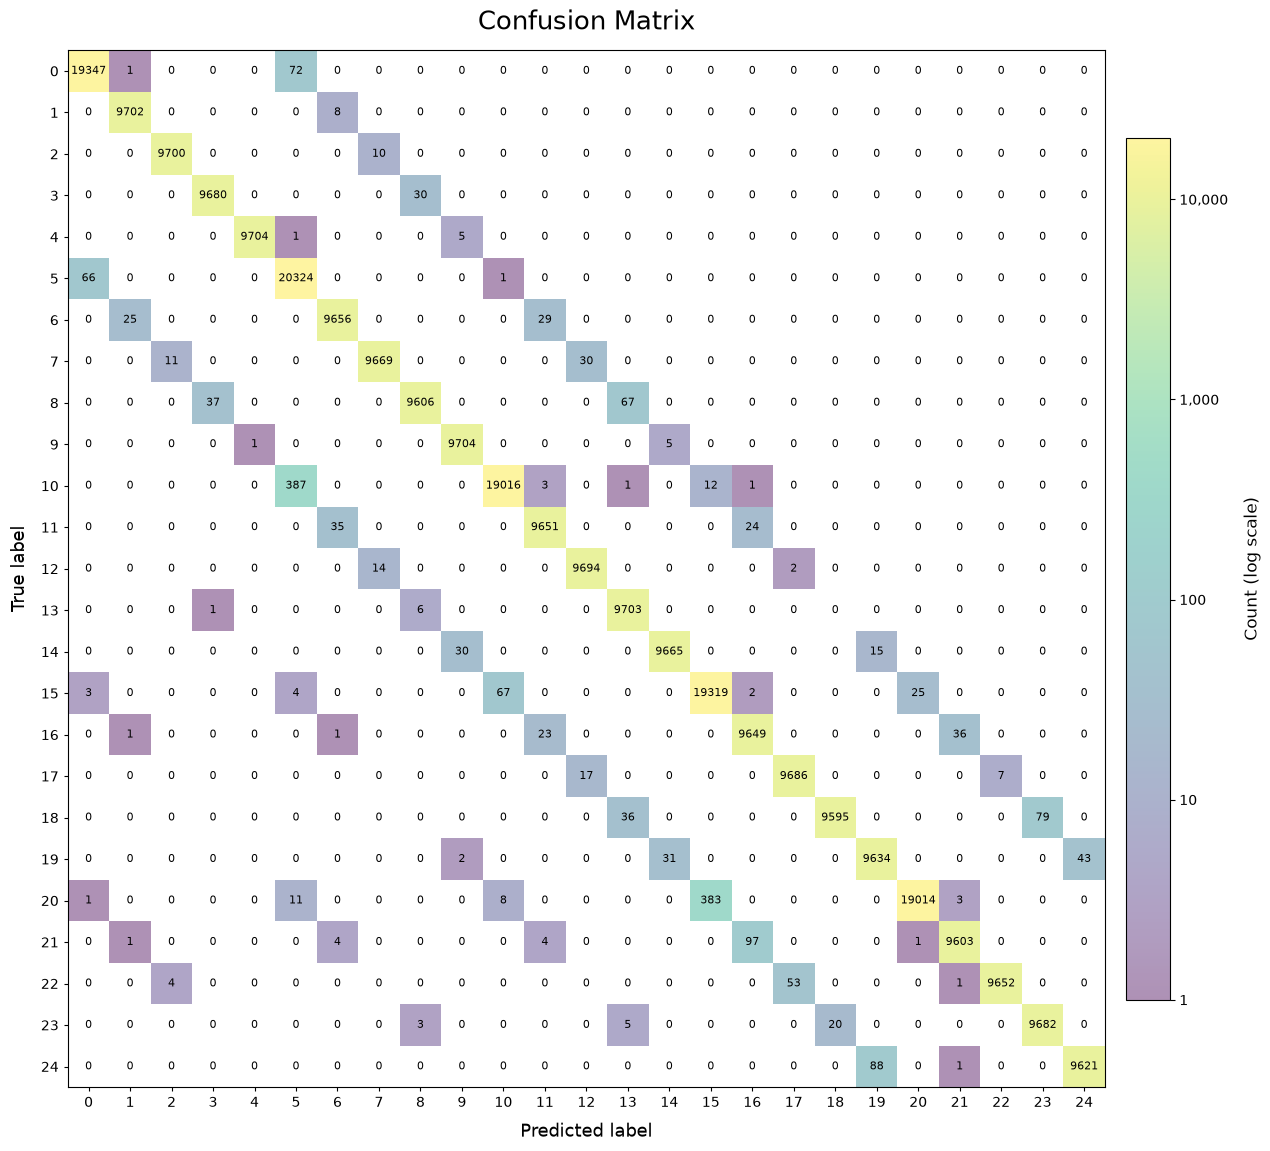

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

CM = np.asarray(cm_25, dtype=np.int64)
class_ids = np.arange(CM.shape[0])
masked_counts = np.ma.masked_equal(CM, 0)
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42}):
    fig, ax = plt.subplots(figsize=(12.5, 11.4), constrained_layout=True)
    edges = np.arange(CM.shape[0] + 1) - 0.5
    mesh = ax.pcolormesh(
        edges, edges, masked_counts,
        norm=LogNorm(vmin=1, vmax=int(CM.max())),
        shading="flat", alpha=0.43, rasterized=False,
    )
    ax.set_xlim(-0.5, CM.shape[1] - 0.5)
    ax.set_ylim(CM.shape[0] - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks(class_ids)
    ax.set_yticks(class_ids)
    ax.tick_params(axis="both", labelsize=10, length=3)
    ax.set_xlabel("Predicted label", fontsize=13, labelpad=9)
    ax.set_ylabel("True label", fontsize=13, labelpad=9)
    ax.set_title("Confusion Matrix", fontsize=19, pad=15)
    for i in class_ids:
        for j in class_ids:
            ax.text(j, i, str(int(CM[i, j])),
                    ha="center", va="center", fontsize=8.0)
    colorbar = fig.colorbar(mesh, ax=ax, fraction=0.040, pad=0.020, shrink=0.88)
    colorbar.set_label("Count (log scale)", fontsize=12, labelpad=11)
    ticks = [1, 10, 100, 1000, 10000]
    colorbar.set_ticks(ticks)
    colorbar.set_ticklabels([f"{value:,}" for value in ticks])
    colorbar.minorticks_off()
    plt.show()
    plt.close(fig)


## Generate Validation Data

### Save 100 inputs for STM32 validation

Select the first four windows from each class in `test_dataset`, giving 100 inputs in total. Store the FP32 array with shape `(100, 30, 23)` under the NPZ file's `input` key only. The targets remain in memory as `y_val_stm`; this cell does not save separate label or metadata files. It prepares validation inputs but does not run model inference or a board evaluation.


In [22]:
import os
import json
import numpy as np
import torch
from collections import defaultdict

# ============================================================
# Generate satellite_real_data.npz for ST Edge AI / STM32Cube.AI validation
# - Save only the input array in the NPZ file
# - Labels remain in memory; only inputs are saved
# ============================================================

SAVE_DIR = "embedded"
os.makedirs(SAVE_DIR, exist_ok=True)

NPZ_PATH = os.path.join(SAVE_DIR, f"satellite_real_data_{seq_length}.npz")

NUM_VALIDATION_SAMPLES = 100
NUM_CLASSES = 25
SEQ_LENGTH = seq_length
NUM_FEATURES = len(features_to_keep)

SAMPLES_PER_CLASS = NUM_VALIDATION_SAMPLES // NUM_CLASSES

print("Generating STM32 validation data...")
print(f"Target samples: {NUM_VALIDATION_SAMPLES}")
print(f"Samples per class: {SAMPLES_PER_CLASS}")
print(f"Expected input shape: ({NUM_VALIDATION_SAMPLES}, {SEQ_LENGTH}, {NUM_FEATURES})")

selected_x = []
selected_y = []

class_counts = defaultdict(int)

for i in range(len(test_dataset)):
    x, y = test_dataset[i]

    if torch.is_tensor(y):
        y_int = int(y.item())
    else:
        y_int = int(y)

    if y_int < 0 or y_int >= NUM_CLASSES:
        continue

    if class_counts[y_int] >= SAMPLES_PER_CLASS:
        continue

    if torch.is_tensor(x):
        x_np = x.detach().cpu().numpy()
    else:
        x_np = np.asarray(x)

    x_np = x_np.astype(np.float32)

    if x_np.shape != (SEQ_LENGTH, NUM_FEATURES):
        raise ValueError(
            f"Invalid sample shape at index {i}: {x_np.shape}, "
            f"expected ({SEQ_LENGTH}, {NUM_FEATURES})"
        )

    selected_x.append(x_np)
    selected_y.append(y_int)
    class_counts[y_int] += 1

    if len(selected_x) >= NUM_VALIDATION_SAMPLES:
        break

missing_classes = [
    c for c in range(NUM_CLASSES)
    if class_counts[c] < SAMPLES_PER_CLASS
]

if missing_classes:
    raise RuntimeError(
        f"Insufficient validation samples for some classes: {missing_classes}\n"
        f"class_counts: {dict(class_counts)}"
    )

X_val_stm = np.stack(selected_x, axis=0).astype(np.float32)
y_val_stm = np.asarray(selected_y, dtype=np.int64)

# Important:
# Store only inputs in the NPZ file used for STM32Cube.AI / ST Edge AI validation.
# Mixing label/metadata in the same NPZ can cause selector or output array errors.
np.savez(NPZ_PATH, input=X_val_stm)

print("-" * 60)
print("satellite_real_data.npz created")
print("NPZ saved at:", NPZ_PATH)
print("input shape:", X_val_stm.shape)
print("input dtype:", X_val_stm.dtype)
print("NPZ entries:", np.load(NPZ_PATH).files)
print("label shape:", y_val_stm.shape)
print("class distribution:")
for c in range(NUM_CLASSES):
    print(f"  class {c:02d}: {class_counts[c]}")
print("-" * 60)

Generating STM32 validation data...
Target samples: 100
Samples per class: 4
Expected input shape: (100, 30, 23)
------------------------------------------------------------
satellite_real_data.npz created
NPZ saved at: embedded\satellite_real_data_30.npz
input shape: (100, 30, 23)
input dtype: float32
NPZ entries: ['input']
label shape: (100,)
class distribution:
  class 00: 4
  class 01: 4
  class 02: 4
  class 03: 4
  class 04: 4
  class 05: 4
  class 06: 4
  class 07: 4
  class 08: 4
  class 09: 4
  class 10: 4
  class 11: 4
  class 12: 4
  class 13: 4
  class 14: 4
  class 15: 4
  class 16: 4
  class 17: 4
  class 18: 4
  class 19: 4
  class 20: 4
  class 21: 4
  class 22: 4
  class 23: 4
  class 24: 4
------------------------------------------------------------


## Generate Data for C Code

### Generate input arrays for C code

Apply the training scaler to the test data and find one 30-row window per class without crossing a block boundary. Prefer a block containing only the target class; otherwise, look for a window whose final row has that class label. Flatten each input into 690 values and save the arrays and expected-label table in `test_samples.h`. This header contains test inputs, not the CNN implementation or board execution results.


In [23]:
# ============================================================
# Generate C samples for MCU validation
# - Use test_df as the data source
# - Respect the block-wise split
# - Extract sequences only within a single Global_Block_ID
# - Use the same scaler and feature order as training and evaluation
# ============================================================

import os
import joblib
import numpy as np
import pandas as pd

print("Generating C samples from test_df...")

assert "Global_Block_ID" in test_df.columns, "test_df is missing the Global_Block_ID column."
assert "Combined_Label" in test_df.columns, "test_df missing Combined_Label column."

# Reuse the scaler fitted in the preprocessing cell; no separate pkl input is required.
if "scaler" not in globals() or not hasattr(scaler, "mean_"):
    raise RuntimeError("Run the data normalization and X/y preparation cell first.")

seq_length = SEQ_LENGTH
num_features = len(features_to_keep)
SAMPLE_SIZE = seq_length * num_features

print(f"C sample input size: {seq_length} x {num_features} = {SAMPLE_SIZE} floats")
print("Number of features:", num_features)
print("Feature list:")
for i, f in enumerate(features_to_keep):
    print(f"{i:02d}: {f}")

# ------------------------------------------------------------
# Sort test_df
# ------------------------------------------------------------

sort_cols = ["Global_Block_ID"]
if "Timestamp" in test_df.columns:
    sort_cols.append("Timestamp")

test_export_df = test_df.sort_values(sort_cols).reset_index(drop=True).copy()

# ------------------------------------------------------------
# Create X and apply the scaler
# ------------------------------------------------------------

X_raw = test_export_df[features_to_keep].copy()
X_raw = X_raw.apply(pd.to_numeric, errors="coerce").fillna(0)

X_scaled = scaler.transform(X_raw).astype(np.float32)

y = test_export_df["Combined_Label"].astype(int).values
groups = test_export_df["Global_Block_ID"].astype(str).values

assert len(X_scaled) == len(y) == len(groups)

# ------------------------------------------------------------
# Build an index for each block
# ------------------------------------------------------------

block_index_map = {}

for block_id, idxs in test_export_df.groupby("Global_Block_ID", sort=False).groups.items():
    idxs = np.array(list(idxs), dtype=np.int64)
    block_index_map[str(block_id)] = idxs

print("Number of test blocks:", len(block_index_map))


# ------------------------------------------------------------
# Extract block-internal sequences for a specific label
# ------------------------------------------------------------

def find_block_pure_sequence(target_label):
    """
    Extract sequences with target_label from within Global_Block_ID.
    Priority:
    1. First block entirely of target_label with length >= seq_length
    2. Sequence within a block whose last label equals target_label
    """

    # 1) Prefer blocks containing only the target label
    for block_id, idxs in block_index_map.items():
        block_labels = y[idxs]

        if len(idxs) < seq_length:
            continue

        if np.all(block_labels == target_label):
            start_idx = idxs[0]
            end_idx = start_idx + seq_length

            # Indices within a block must be contiguous in the sorted test_export_df
            candidate_idxs = np.arange(start_idx, end_idx)

            if np.all(groups[candidate_idxs] == block_id):
                return X_scaled[candidate_idxs], block_labels[:seq_length], block_id, "pure"

    # 2) Fall back to sliding windows within each block
    for block_id, idxs in block_index_map.items():
        if len(idxs) < seq_length:
            continue

        for local_start in range(0, len(idxs) - seq_length + 1):
            candidate_idxs = idxs[local_start: local_start + seq_length]
            window_labels = y[candidate_idxs]

            if window_labels[-1] == target_label:
                purity = "pure" if np.all(window_labels == target_label) else "impure"
                return X_scaled[candidate_idxs], window_labels, block_id, purity

    return None, None, None, "not found"


# ------------------------------------------------------------
# Generate C arrays
# ------------------------------------------------------------

def export_pure_c_array(target_label):
    target_sequence, window_labels, block_id, purity = find_block_pure_sequence(target_label)

    if target_sequence is None:
        return f"// WARNING: No Type {target_label} sequence found in test_df.\n"

    assert target_sequence.shape == (seq_length, num_features), (
        f"Invalid sequence shape: {target_sequence.shape}"
    )

    flat_seq = target_sequence.flatten()

    label_list = ", ".join([str(int(v)) for v in window_labels])

    c_code = ""
    c_code += (
        f"// {purity} Type {target_label} data\n"
        f"// Block: {block_id}\n"
        f"// Window labels: [{label_list}]\n"
        f"// Shape: {seq_length} x {num_features} = {SAMPLE_SIZE} floats\n"
    )

    c_code += f"static const float sample_type_{target_label}[TEST_SAMPLE_SIZE] = {{\n    "

    values = [f"{val:.6f}f" for val in flat_seq]
    line_width = 8

    for i in range(0, len(values), line_width):
        c_code += ", ".join(values[i:i + line_width])

        if i + line_width < len(values):
            c_code += ",\n    "

    c_code += "\n};\n"

    return c_code


# ------------------------------------------------------------
# Generate the header
# ------------------------------------------------------------

types_to_extract = list(range(NUM_CLASSES))

final_c_header_content = ""
final_c_header_content += "#ifndef __TEST_SAMPLES_H__\n"
final_c_header_content += "#define __TEST_SAMPLES_H__\n\n"

final_c_header_content += "#include <stdint.h>\n\n"

final_c_header_content += f"#define TEST_SEQ_LENGTH {seq_length}\n"
final_c_header_content += f"#define TEST_NUM_FEATURES {num_features}\n"
final_c_header_content += f"#define TEST_SAMPLE_SIZE {SAMPLE_SIZE}\n"
final_c_header_content += f"#define TEST_NUM_CLASSES {NUM_CLASSES}\n\n"

final_c_header_content += "// Feature order:\n"
for i, f in enumerate(features_to_keep):
    final_c_header_content += f"// [{i:02d}] {f}\n"
final_c_header_content += "\n"

for t in types_to_extract:
    print(f"Searching for Type {t} block-local sequence...")
    final_c_header_content += export_pure_c_array(t) + "\n"

# sample pointer table
final_c_header_content += "static const float* test_samples[TEST_NUM_CLASSES] = {\n    "
final_c_header_content += ",\n    ".join(
    [f"sample_type_{t}" for t in types_to_extract]
)
final_c_header_content += "\n};\n\n"

# expected label table
final_c_header_content += "static const int32_t test_labels[TEST_NUM_CLASSES] = {\n    "
final_c_header_content += ", ".join([str(t) for t in types_to_extract])
final_c_header_content += "\n};\n\n"

final_c_header_content += "#endif // __TEST_SAMPLES_H__\n"

# ------------------------------------------------------------
# Save the header
# ------------------------------------------------------------

os.makedirs("embedded", exist_ok=True)

output_path = "embedded/test_samples.h"

with open(output_path, "w", encoding="utf-8") as f:
    f.write(final_c_header_content)

print("\ntest_samples.h generated!")
print("Saved at:", output_path)

Generating C samples from test_df...
C sample input size: 30 x 23 = 690 floats
Number of features: 23
Feature list:
00: CCSDS_APID
01: CCSDS_DataLen
02: CSP_Priority
03: CSP_Source
04: CSP_Dest
05: CSP_DPort
06: CSP_SPort
07: CSP_Flags
08: Payload_Len
09: Time_Delta_Log
10: Flags_Change
11: Payload_Diff
12: APID_Count
13: Global_Time_Delta_Log
14: APID_Time_Delta_Log
15: APID_Changed_Roll10
16: CCSDS_DataLen_AbsDiff
17: CCSDS_SeqCount_AbsDiff
18: Packet_Rate_Roll10_Log
19: CSP_Nonzero_Roll10
20: CSP_Route_Changed_Roll10
21: Payload_Len_RollStd10
22: P_Entropy_Log_RollStd10
Number of test blocks: 301
Searching for Type 0 block-local sequence...
Searching for Type 1 block-local sequence...
Searching for Type 2 block-local sequence...
Searching for Type 3 block-local sequence...
Searching for Type 4 block-local sequence...
Searching for Type 5 block-local sequence...
Searching for Type 6 block-local sequence...
Searching for Type 7 block-local sequence...
Searching for Type 8 block-local 